# 00 — Data: Pump it Up (water-pump condition, Tanzania)

**Task.** Predict `status_group` ∈ {functional, functional needs repair, non functional} for each pump. **Metric: accuracy.**

This notebook is version-independent. It covers the raw data, its quirks, and the **validation scheme every later notebook shares**. Feature engineering and models belong to the `vN` notebooks.

It ends with a list of hypotheses. Each `vN` notebook tests some of them.

In [1]:
import sys, warnings
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 140)
V = load_version('v1')
raw = V.DataPipeline().load_train()      # also runs the swapped-file guard
test = V.DataPipeline().load_test()
print('train', raw.shape, '| test', test.shape)

train (59400, 41) | test (14850, 40)


## 1. Target
The classes are imbalanced. The minority class, *needs repair*, is only ~7%. The metric is accuracy, so a model can ignore it and still look fine.

status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: count, dtype: float64
accuracy of always predicting the majority class: 0.5431


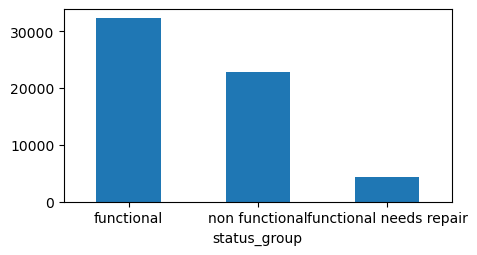

In [2]:
vc = raw[TARGET].value_counts()
print((vc / len(raw)).round(3))
print('accuracy of always predicting the majority class:', round(vc.iloc[0] / len(raw), 4))
vc.plot.bar(rot=0, figsize=(5, 2.5)); plt.show()

## 2. Missing data: real NaNs and *disguised* NaNs
Some columns use `0` as a missing-value placeholder. v1–v7 all apply `replace(0, nan)` to five columns. The first table below shows how often each is 0.

In [3]:
cols = ['longitude', 'latitude', 'construction_year', 'population', 'gps_height']
print('fraction == 0 :'); print((raw[cols] == 0).mean().round(3).to_string())
print('\nreal NaNs:'); print(raw.isnull().mean()[lambda s: s > 0].round(3).to_string())

fraction == 0 :


longitude            0.031
latitude             0.000
construction_year    0.349
population           0.360
gps_height           0.344

real NaNs:
funder               0.061
installer            0.062
wpt_name             0.000
subvillage           0.006
public_meeting       0.056
scheme_management    0.065
scheme_name          0.485
permit               0.051


**Finding: `latitude` is never 0, yet `longitude` is 0 for ~3% of rows.** Look at what latitude holds on exactly those rows.

In [4]:
bad = raw.longitude == 0
print('rows with longitude == 0:', bad.sum())
print('their latitude values   :', raw.loc[bad, 'latitude'].unique())
print('rows with latitude > -1e-4 (placeholder):', (raw.latitude > -1e-4).sum())

rows with longitude == 0: 1812
their latitude values   : [-2.e-08]
rows with latitude > -1e-4 (placeholder): 1812


The placeholder for latitude is **`-2e-08`**, not `0`. The pipeline's `replace(0, nan)` therefore never touches it. After imputation these 1,812 pumps get a region-median longitude but still have latitude ≈ 0, which is a point on the equator, nowhere near Tanzania. Every later version inherits this, and v4's `geo_cluster` clusters on these coordinates. **Hypothesis H1: fixing it helps.** The v2 notebook tests it as an extra row.

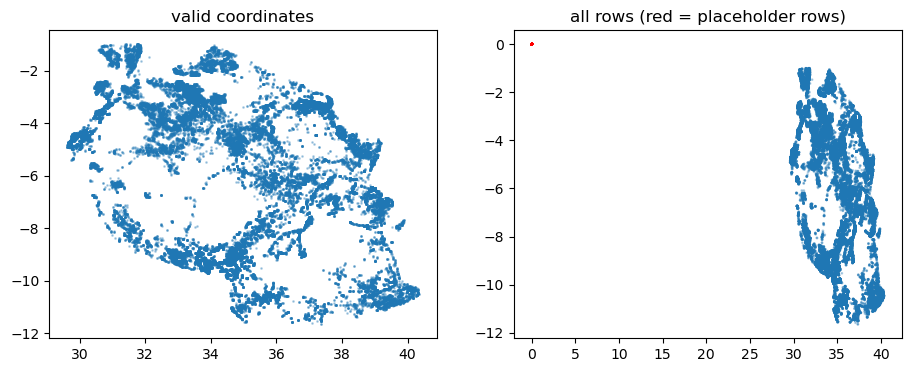

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ok = ~bad
ax[0].scatter(raw.longitude[ok], raw.latitude[ok], s=1, alpha=.3); ax[0].set_title('valid coordinates')
ax[1].scatter(raw.longitude, raw.latitude, s=1, alpha=.3, c=bad.map({True: 'red', False: 'tab:blue'}))
ax[1].set_title('all rows (red = placeholder rows)'); plt.show()

## 3. Missingness is not random
The next plot shows whether *a value being missing* carries signal. If it does, a missingness flag (tested in v2) should help.

In [6]:
rows = []
for c in ['funder', 'installer', 'scheme_name', 'scheme_management', 'public_meeting', 'permit']:
    m = raw[c].isnull()
    rows.append((c, m.mean(), *raw.loc[m, TARGET].value_counts(normalize=True).reindex(vc.index).fillna(0).values))
rows.append(('construction_year==0', (raw.construction_year == 0).mean(),
             *raw.loc[raw.construction_year == 0, TARGET].value_counts(normalize=True).reindex(vc.index).fillna(0).values))
t = pd.DataFrame(rows, columns=['column', 'frac_missing', *vc.index]).set_index('column').round(3)
t.loc['(overall)'] = [np.nan, *(vc / len(raw)).round(3).values]
t

,frac_missing,functional,non functional,functional needs repair
column,,,,
funder,0.061,0.545,0.335,0.120
installer,0.062,0.547,0.332,0.120
scheme_name,0.485,0.517,0.412,0.071
scheme_management,0.065,0.483,0.459,0.058
public_meeting,0.056,0.503,0.450,0.047
permit,0.051,0.547,0.354,0.098
construction_year==0,0.349,0.510,0.404,0.086
(overall),NaN,0.543,0.384,0.073


## 4. Categorical cardinality
High-cardinality text columns (`funder`, `installer`) are messy. v5 tests cleaning them. Native categorical support in v2 has to cope with these, since frequency encoding ignored them.

In [7]:
card = raw.select_dtypes('object').nunique().sort_values(ascending=False)
print(card.to_string())
print('\nconstant columns:', [c for c in raw.columns if raw[c].nunique() == 1])
print('exact-duplicate feature rows (ignoring id/label):', raw.drop(columns=['id', TARGET]).duplicated().sum())

wpt_name                 37399
subvillage               19287
scheme_name               2695
installer                 2145
ward                      2092
funder                    1896
date_recorded              356
lga                        125
region                      21
extraction_type             18
extraction_type_group       13
management                  12
scheme_management           11
source                      10
basin                        9
water_quality                8
extraction_type_class        7
payment                      7
payment_type                 7
source_type                  7
waterpoint_type              7
quality_group                6
waterpoint_type_group        6
management_group             5
quantity                     5
quantity_group               5
source_class                 3
status_group                 3
public_meeting               2
permit                       2
recorded_by                  1

constant columns: ['recorded_by']


exact-duplicate feature rows (ignoring id/label): 37


In [8]:
for c in ['funder', 'installer']:
    s = raw[c].str.lower().str.strip()
    print(f'{c}: {raw[c].nunique()} raw -> {s.nunique()} after lower/strip; top-10 cover {s.value_counts(normalize=True).head(10).sum():.0%} of rows')

funder: 1896 raw -> 1896 after lower/strip; top-10 cover 40% of rows
installer: 2145 raw -> 1935 after lower/strip; top-10 cover 49% of rows


## 5. Which raw columns predict the target on their own?

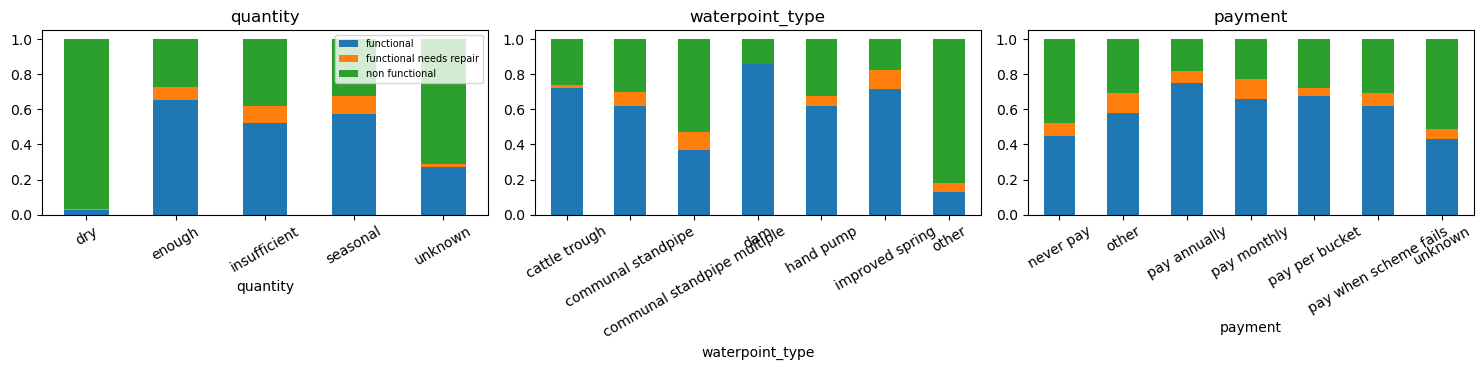

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, ['quantity', 'waterpoint_type', 'payment']):
    pd.crosstab(raw[c], raw[TARGET], normalize='index').plot.bar(stacked=True, ax=a, legend=False, rot=30)
    a.set_title(c)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

`quantity == dry` is ~97% non-functional, a very strong single feature. That suggests simple models will already do well, and later gains will be small.

In [10]:
r = pd.crosstab(raw.region, raw[TARGET], normalize='index').round(2)
r['n'] = raw.region.value_counts()
print(r.sort_values('non functional').to_string())
print('\nconstruction_year range (non-zero):', raw.loc[raw.construction_year > 0, 'construction_year'].agg(['min', 'max']).tolist())
print('date_recorded range:', raw.date_recorded.min(), '->', raw.date_recorded.max())

status_group   functional  functional needs repair  non functional     n
region                                                                  
Iringa               0.78                     0.02            0.19  5294
Arusha               0.68                     0.05            0.26  3350
Kigoma               0.48                     0.21            0.30  2816
Shinyanga            0.56                     0.13            0.31  4982
Manyara              0.62                     0.06            0.32  1583
Kilimanjaro          0.60                     0.07            0.32  4379
Ruvuma               0.56                     0.06            0.38  2640
Mbeya                0.50                     0.11            0.39  4639
Kagera               0.52                     0.09            0.39  3316
Morogoro             0.53                     0.07            0.40  4006
Pwani                0.59                     0.01            0.40  2635
Tanga                0.56                     0.03 

## 6. Is the test set like the training set?
If the test set comes from the same distribution, random folds are a fair local proxy for the leaderboard.

In [11]:
for c in ['region', 'quantity', 'payment']:
    a = raw[c].value_counts(normalize=True); b = test[c].value_counts(normalize=True)
    print(c, 'max abs diff in category share:', round(float(a.sub(b, fill_value=0).abs().max()), 4))
print('test construction_year==0:', round((test.construction_year == 0).mean(), 3), '| train:', round((raw.construction_year == 0).mean(), 3))
print('train/test date ranges:', raw.date_recorded.max(), test.date_recorded.min(), test.date_recorded.max())

region max abs diff in category share: 0.0054
quantity max abs diff in category share: 0.0027
payment max abs diff in category share: 0.0034
test construction_year==0: 0.354 | train: 0.349
train/test date ranges: 2013-12-03 2001-03-26 2013-12-03


## 7. Validation scheme (shared by every notebook)

- **Stratified 5-fold, `shuffle=True`, `random_state=42`**, implemented in `common.folds()`.
- Stratified, because the minority class is only 7%.
- Not grouped. There is no session or group id, and `id` has no duplicates. Pumps in the same village *do* share traits, and nearby rows may be near-duplicates (see the exact-duplicate count above). Random folds may therefore be slightly **optimistic** versus the test set. The leaderboard is the final check.
- Features are **fit inside each fold** (`cv_xgb`), so nothing learned from the validation rows leaks into training.
- All results are appended to `results.jsonl`. Compare rows by their **mean ± std across folds**. A difference smaller than the fold std is noise.

In [12]:
from sklearn.preprocessing import LabelEncoder
yy = LabelEncoder().fit_transform(raw[TARGET])
for i, (tr, va) in enumerate(folds(yy), 1):
    print(f'fold {i}: train {len(tr)}, val {len(va)}, val class shares', np.bincount(yy[va]) / len(va))

fold 1: train 47520, val 11880, val class shares [0.54309764 0.0726431  0.38425926]
fold 2: train 47520, val 11880, val class shares [0.54309764 0.0726431  0.38425926]
fold 3: train 47520, val 11880, val class shares [0.54309764 0.0726431  0.38425926]
fold 4: train 47520, val 11880, val class shares [0.54309764 0.07272727 0.38417508]
fold 5: train 47520, val 11880, val class shares [0.54301347 0.07272727 0.38425926]


## 8. Hypotheses to test in the version notebooks

| # | Hypothesis | Tested in |
|---|---|---|
| H1 | Fixing the latitude placeholder (`-2e-8`) helps | v2 (extra row) |
| H2 | Native categoricals beat frequency encoding + top-15 MI cut (high-cardinality columns lose information otherwise) | v2 |
| H3 | Region-median imputation beats global median (geography varies a lot) | v2 |
| H4 | Missingness flags carry signal | v2 |
| H5 | Balanced class weights help the 7% class but may **cost accuracy** (the metric ignores class balance) | v2 |
| H6 | Hyperparameter search + early stopping gives a small, real gain | v3 |
| H7 | `geo_cluster`, `funder`/`installer` cleaning, interactions each add a small gain | v4–v6 |
| H8 | An XGBoost+LightGBM blend beats either alone | v7 |